In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [42]:
data= {
    'Age':[20, 22,25,27,30,35,38,40,42,45,50,52, 55,58, 60],
    'Income':[20000,22000,25000,27000,30000,40000,42000,45000,48000,50000,60000,65000,70000,75000,80000],
    'SpendingingScore':[80,85,78,82,75,60,65,55,58,50,30,25,35,20,27]
}

In [43]:
df= pd.DataFrame(data)
print('Customer Dataset:')
print(df)

Customer Dataset:
    Age  Income  SpendingingScore
0    20   20000                80
1    22   22000                85
2    25   25000                78
3    27   27000                82
4    30   30000                75
5    35   40000                60
6    38   42000                65
7    40   45000                55
8    42   48000                58
9    45   50000                50
10   50   60000                30
11   52   65000                25
12   55   70000                35
13   58   75000                20
14   60   80000                27


In [44]:
print('Missing Dataset:')
print(df.isnull().sum())

Missing Dataset:
Age                 0
Income              0
SpendingingScore    0
dtype: int64


In [45]:
X=df[['Age' ,'Income','SpendingingScore']]

In [46]:
scaler= StandardScaler()
X_scaler= scaler.fit_transform(X)

In [47]:
inertia= []
for k in range(1,11):
    kmeans= KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaler)
    inertia.append(kmeans.inertia_)

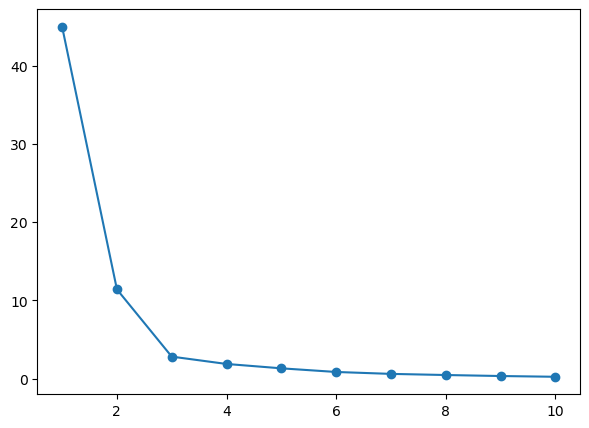

In [48]:
plt.figure(figsize=(7,5))
plt.plot(
    range(1,11),
    inertia,
    marker= 'o'
)


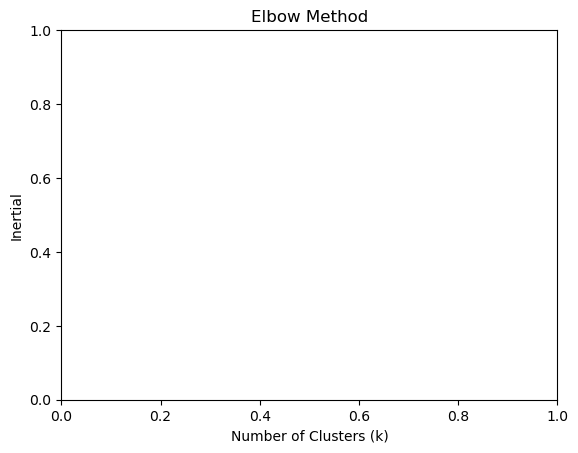

In [49]:
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertial')
plt.title('Elbow Method')

plt.show()

In [50]:
kmeans=KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

In [52]:
clusters= kmeans.fit_predict(X_scaler)
df['Cluster'] = clusters
print('Customer Cluster:')
print(df)

Customer Cluster:
    Age  Income  SpendingingScore  Cluster
0    20   20000                80        2
1    22   22000                85        2
2    25   25000                78        2
3    27   27000                82        2
4    30   30000                75        2
5    35   40000                60        0
6    38   42000                65        0
7    40   45000                55        0
8    42   48000                58        0
9    45   50000                50        0
10   50   60000                30        1
11   52   65000                25        1
12   55   70000                35        1
13   58   75000                20        1
14   60   80000                27        1


Text(0.5, 1.0, 'Customer Segmentation using K_Means')

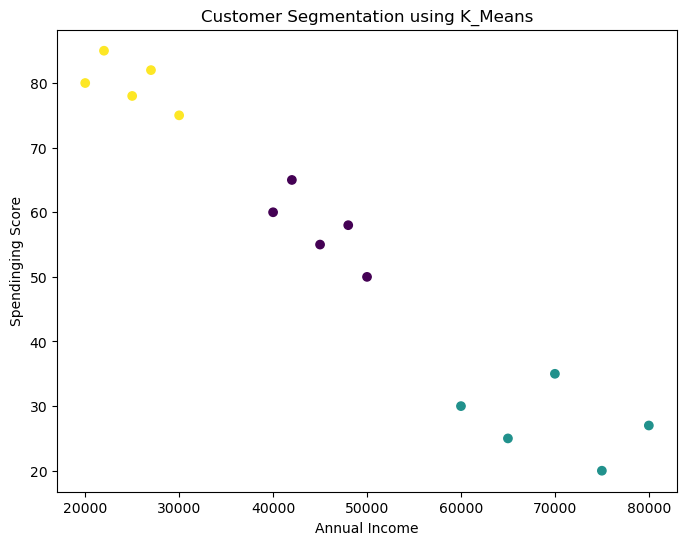

In [55]:
plt.figure(figsize=(8,6))
plt.scatter(
    df['Income'],
    df['SpendingingScore'],
    c=df['Cluster']
)
plt.xlabel('Annual Income')
plt.ylabel('Spendinging Score')
plt.title('Customer Segmentation using K_Means')
